# Anomaly Screening: Comparing Detectors on Rare Positives

**Family:** End-to-end project | **Dataset:** `breast_cancer` | **Task:** anomaly_detection

Compare three anomaly detectors over many random draws of the rare class, instead of trusting one split. A proxy for industrial anomaly detection, for which no open data could be downloaded.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Rank rows by how unusual they are when only a small share of rows are abnormal.

## 2. Business or research context

Industrial and screening systems have few examples of failures. A detector is judged by how it ranks the rare cases. With few positives one random draw is unreliable, so we repeat the draw 30 times.

## 3. Dataset documentation

**Breast Cancer Wisconsin (Diagnostic)**, UCI, licence CC BY 4.0, DOI 10.24432/C5DW2B. 569 rows, 30 numeric features (mean, standard error and worst value of ten nucleus properties computed from digitised fine needle aspirate images). Target `malignant` (1 malignant, 0 benign). No missing values. Limits: one institution, small sample.

**Construction.** Benign rows are normal. For each repetition we draw malignant rows equal to 5 percent of the benign count as anomalies. This is a **constructed benchmark**, not a real anomaly study.

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Liu, F. T., Ting, K. M. and Zhou, Z. H. (2008). *Isolation Forest*. IEEE ICDM 2008, pp. 413-422. https://doi.org/10.1109/ICDM.2008.17 Verification: Crossref 2026-11-17
- Breunig, M. M., Kriegel, H. P., Ng, R. T. and Sander, J. (2000). *LOF: identifying density-based local outliers*. ACM SIGMOD Record 29(2):93-104. https://doi.org/10.1145/335191.335388 Verification: Crossref 2026-11-17

Isolation Forest and Local Outlier Factor are compared with a one class SVM.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "anomaly_screening"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("breast_cancer")
X, y = bundle.X.values, bundle.y.values
print(X.shape, "benign:", int((y == 0).sum()), "malignant:", int((y == 1).sum()))

(569, 30) benign: 357 malignant: 212


## 5. Exploratory analysis

How different are the two groups on a few features.

In [3]:
names = bundle.X.columns
d = (X[y == 1].mean(axis=0) - X[y == 0].mean(axis=0)) / X.std(axis=0)
display(pd.Series(d, index=names).abs().sort_values(ascending=False).head(5).round(2).to_frame("standardised mean difference"))

,standardised mean difference
worst concave points,1.64
worst perimeter,1.62
mean concave points,1.61
worst radius,1.61
mean perimeter,1.54


## 6. Preprocessing

Each repetition: draw anomalies, split 70/30 stratified, fit the scaler on the training part, fit detectors on the training part without labels, score the test part.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
def draw(seed):
    rng = np.random.default_rng(seed)
    benign = np.where(y == 0)[0]
    mal = rng.choice(np.where(y == 1)[0], int(0.05 * len(benign)), replace=False)
    rows = np.sort(np.r_[benign, mal])
    Xs, ys = X[rows], y[rows]
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=seed)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr, yte
print("anomalies per draw:", int(0.05 * (y == 0).sum()))

anomalies per draw: 17


## 7. Model selection

Detectors are Isolation Forest, Local Outlier Factor (novelty mode) and One-Class SVM. No labels are used for fitting, and no selection on test rows.

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
detectors = {"isolation_forest": lambda: IsolationForest(n_estimators=200, random_state=SEED),
             "lof": lambda: LocalOutlierFactor(n_neighbors=20, novelty=True),
             "one_class_svm": lambda: OneClassSVM(nu=0.05, gamma="scale")}
print(list(detectors))

['isolation_forest', 'lof', 'one_class_svm']


## 8. Model training

30 repetitions, each fitting every detector on training rows.

In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score
results = {n: {"roc": [], "pr": []} for n in detectors}
for rep in range(30):
    Xa, Xb, ya, yb = draw(rep)
    for n, make in detectors.items():
        det = make().fit(Xa)
        score = -det.score_samples(Xb) if n != "one_class_svm" else -det.decision_function(Xb)
        results[n]["roc"].append(roc_auc_score(yb, score)); results[n]["pr"].append(average_precision_score(yb, score))
print("done")

done


## 9. Evaluation

Mean and standard deviation over 30 draws, with the random ranking as the PR-AUC floor (about 0.048).

In [7]:
summary = pd.DataFrame({n: {"ROC_AUC_mean": np.mean(r["roc"]), "ROC_AUC_std": np.std(r["roc"], ddof=1), "PR_AUC_mean": np.mean(r["pr"]), "PR_AUC_std": np.std(r["pr"], ddof=1)} for n, r in results.items()}).T
display(summary.round(3))
METRICS = {f"{n}_{k}": float(v) for n, row in summary.iterrows() for k, v in row.items()}
METRICS["random_PR_AUC"] = float(0.05 / 1.05)
CONFIG = {"repetitions": 30, "anomaly_share": 0.05, "test_size": 0.3}
EXTRA = {"summary": summary.round(4).reset_index().to_dict("records")}
ALGORITHM = "IsolationForest, LOF, OneClassSVM"

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="breast_cancer", task="anomaly_detection", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,PR_AUC_std
isolation_forest,0.957,0.037,0.676,0.182
lof,0.944,0.044,0.581,0.176
one_class_svm,0.909,0.053,0.410,0.132


saved: experiments/results/anomaly_screening.json


,metric
isolation_forest_ROC_AUC_mean,0.9572
isolation_forest_ROC_AUC_std,0.0367
isolation_forest_PR_AUC_mean,0.6758
isolation_forest_PR_AUC_std,0.1824
lof_ROC_AUC_mean,0.9443
lof_ROC_AUC_std,0.0439
lof_PR_AUC_mean,0.5807
lof_PR_AUC_std,0.1761
one_class_svm_ROC_AUC_mean,0.9086
one_class_svm_ROC_AUC_std,0.0528


## 10. Comparison

Paired differences between detectors across the same 30 draws.

Isolation Forest minus LOF, ROC-AUC: mean 0.013 | 95% interval [-0.0116  0.0492] | IF better in 21 of 30 draws


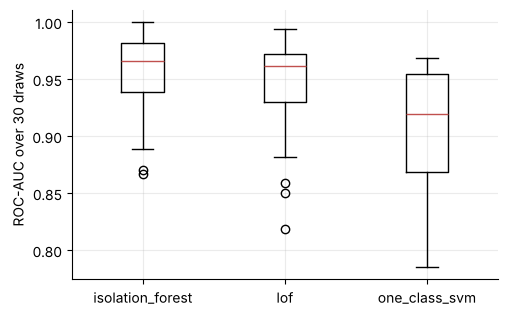

In [8]:
diff = np.array(results["isolation_forest"]["roc"]) - np.array(results["lof"]["roc"])
print("Isolation Forest minus LOF, ROC-AUC: mean", round(float(diff.mean()), 4), "| 95% interval", np.round(np.percentile(diff, [2.5, 97.5]), 4), "| IF better in", int((diff > 0).sum()), "of 30 draws")
fig, ax = plt.subplots(figsize=(5.5, 3.5)); ax.boxplot([results[n]["roc"] for n in detectors], tick_labels=list(detectors)); ax.set_ylabel("ROC-AUC over 30 draws"); save_figure(fig, PROJECT_ID, "boxplot"); plt.show()

## 11. Interpretation

Which features make flagged rows unusual, on one draw.

In [9]:
Xa, Xb, ya, yb = draw(0)
det = IsolationForest(n_estimators=200, random_state=SEED).fit(Xa)
top = np.argsort(det.score_samples(Xb))[:3]
for i in top:
    order = np.argsort(-np.abs(Xb[i]))[:3]
    print("row label", int(yb[i]), "| most unusual:", dict(zip(names[order], np.round(Xb[i][order], 1))))

row label 0 | most unusual: {'concavity error': np.float64(13.3), 'fractal dimension error': np.float64(9.2), 'concave points error': np.float64(8.2)}
row label 1 | most unusual: {'area error': np.float64(5.9), 'mean area': np.float64(4.7), 'worst area': np.float64(4.6)}
row label 1 | most unusual: {'worst area': np.float64(5.4), 'mean area': np.float64(4.6), 'worst perimeter': np.float64(4.4)}


## 12. Limitations

Constructed anomalies from a real class, one dataset, 30 repetitions of a 30 percent split. Real industrial anomalies differ in kind and frequency.

## 13. Final recommendations

Compare detectors over repeated draws, set the alert threshold from the cost of reviewing a case, and validate on real labelled failures before deployment.